회귀 분석 모형 가정 검증

https://support.minitab.com/ko-kr/minitab/help-and-how-to/statistical-modeling/regression/supporting-topics/model-assumptions/validate-model-assumptions/

미니탭 회귀 분석 유형

https://support.minitab.com/ko-kr/minitab/help-and-how-to/statistical-modeling/regression/supporting-topics/basics/regression-analyses-in-minitab/

로지스틱 회귀

https://blog.naver.com/stat833/220080914073

### Case 1: 독립변수 - 전부 연속형, 종속변수 - 연속형
- **선형 회귀 분석 (Linear Regression)**: 가장 기본적인 회귀 분석 기법으로, 독립변수와 종속변수 간의 선형 관계를 모델링합니다.

### Case 2: 독립변수 - 전부 연속형, 종속변수 - 범주형(2개)
- **로지스틱 회귀 분석 (Logistic Regression)**: 종속변수가 두 개의 범주로 나뉘는 경우 사용하며, 독립변수와 종속변수 간의 관계를 확률로 모델링합니다.

### Case 3: 독립변수 - 전부 연속형, 종속변수 - 범주형(3개 이상)
- **다항 로지스틱 회귀 분석 (Multinomial Logistic Regression)**: 종속변수가 세 개 이상의 범주로 나뉘는 경우 사용하며, 각 범주에 대한 확률을 모델링합니다.

### Case 4: 독립변수 - 연속형/범주형 혼합, 종속변수 - 연속형
- **선형 회귀 분석 (Linear Regression)**: 범주형 변수를 더미 변수로 변환하여 선형 회귀 분석을 수행할 수 있습니다.

### Case 5: 독립변수 - 연속형/범주형 혼합, 종속변수 - 범주형(2개)
- **로지스틱 회귀 분석 (Logistic Regression)**: 범주형 독립변수를 더미 변수로 변환하여 로지스틱 회귀 분석을 수행할 수 있습니다.

### Case 6: 독립변수 - 연속형/범주형 혼합, 종속변수 - 범주형(3개 이상)
- **다항 로지스틱 회귀 분석 (Multinomial Logistic Regression)**: 범주형 독립변수를 더미 변수로 변환하여 다항 로지스틱 회귀 분석을 수행할 수 있습니다.

python ols 사용 예시

- https://xiang32.tistory.com/13
- https://wikidocs.net/261974

변수 선택

https://yngie-c.github.io/machine%20learning/2020/09/06/fs_be/

회귀식 규제화
https://coduking.tistory.com/entry/%ED%9A%8C%EA%B7%80%EB%AA%A8%EB%8D%B8-%EB%9D%BC%EC%8F%98Lasso-%EB%A6%BF%EC%A7%80Ridge-%EC%97%98%EB%9D%BC%EC%8A%A4%ED%8B%B1-%EB%84%B7ElasticNet

회귀분석 결과표
https://support.minitab.com/ko-kr/minitab/help-and-how-to/statistical-modeling/regression/how-to/fit-regression-model/interpret-the-results/key-results/

In [1]:
from typing import List, Dict
import pandas as pd
import numpy as np
import statsmodels.api as sm
from sklearn.linear_model import LinearRegression, Lasso, Ridge
from sklearn.model_selection import cross_val_score, KFold
from sklearn.metrics import mean_squared_error, r2_score
import matplotlib.pyplot as plt

from eda_manager.analyze.data_analyze.regression_v1 import VariableSelector


In [2]:
%matplotlib inline

In [3]:
from sklearn.datasets import load_diabetes
d = load_diabetes()
df = pd.DataFrame(d.data, columns=d.feature_names)
df['target'] = d.target
print(df.shape)

(442, 11)


In [4]:
df.head()

,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646,151.0
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204,75.0
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930,141.0
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362,206.0
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641,135.0


선정 변수: ['bmi', 's5', 'bp', 's1', 'sex', 's2']
OLS
ŷ = 152.133 + bmi*529.88 + s5*804.187 + bp*327.215 + s1*-757.93 + sex*-226.507 + s2*538.58


,coef,std_err,t,p_value,ci_low,ci_high
const,152.133484,2.571588,59.159353,3.826468e-210,147.079202,157.187767
bmi,529.879640,65.620195,8.074948,6.687185e-15,400.907581,658.851699
s5,804.187387,80.173048,10.030645,1.938635e-21,646.612678,961.762096
bp,327.215021,62.693179,5.219308,2.786882e-07,203.995814,450.434228
s1,-757.930331,160.434844,-4.724225,3.122573e-06,-1073.254177,-442.606485


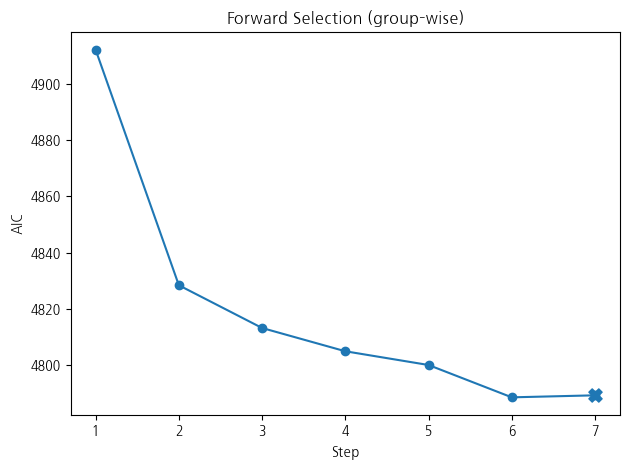

In [5]:
sel = VariableSelector(df, [c for c in df.columns if c!='target'], 'target',
                       criterion="aic", penalty=None, cv=None, problem_type="regression")
vars_sel, fig, hist, final = sel.forward()
print("선정 변수:", vars_sel)
print(final["model_family"])
print(final["equation"])
display(final["coef_table"].head())

선정 변수: ['sex', 'bmi', 'bp', 's1', 's2', 's5']
OLS
ŷ = 152.133 + sex*-226.507 + bmi*529.88 + bp*327.215 + s1*-757.93 + s2*538.58 + s5*804.187


,coef,std_err,t,p_value,ci_low,ci_high
const,152.133484,2.571588,59.159353,3.826468e-210,147.079202,157.187767
sex,-226.506646,59.856617,-3.784154,1.758474e-04,-344.150781,-108.862510
bmi,529.879640,65.620195,8.074948,6.687185e-15,400.907581,658.851699
bp,327.215021,62.693179,5.219308,2.786882e-07,203.995814,450.434228
s1,-757.930331,160.434844,-4.724225,3.122573e-06,-1073.254177,-442.606485


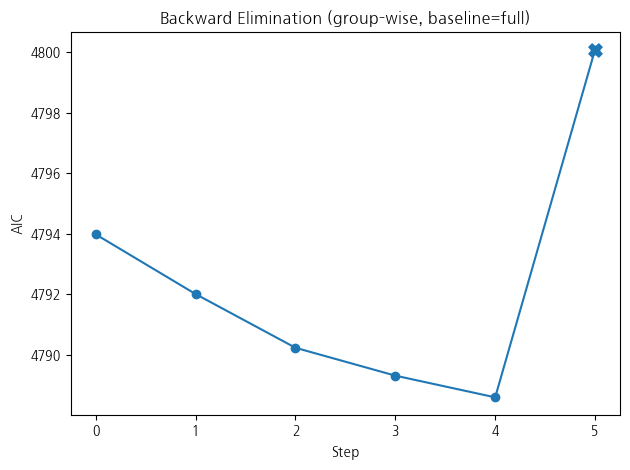

In [6]:
sel = VariableSelector(df, [c for c in df.columns if c!='target'], 'target',
                       criterion="aic", penalty=None, cv=None, problem_type="regression")
vars_sel, fig, hist, final = sel.backward()
print("선정 변수:", vars_sel)
print(final["model_family"])
print(final["equation"])
display(final["coef_table"].head())

선정 변수: ['bmi', 's5', 'bp', 's1']
OLS
ŷ = 152.133 + bmi*605.711 + s5*645.692 + bp*271.276 + s1*-206.67


,coef,std_err,t,p_value,ci_low,ci_high
const,152.133484,2.625473,57.945173,3.193262e-207,146.973360,157.293608
bmi,605.711203,64.008891,9.462923,1.873430e-19,479.907659,731.514747
s5,645.692279,71.407229,9.042394,5.030845e-18,505.347988,786.036570
bp,271.276306,62.369763,4.349484,1.700049e-05,148.694317,393.858296
s1,-206.669533,64.503099,-3.204025,1.454431e-03,-333.444397,-79.894670


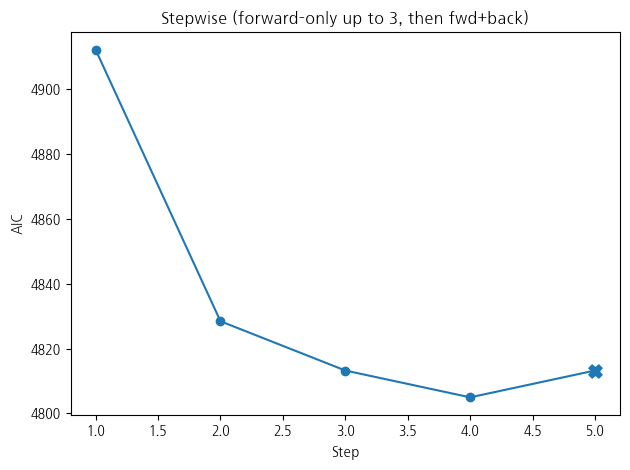

In [7]:
sel = VariableSelector(df, [c for c in df.columns if c!='target'], 'target',
                       criterion="aic", penalty=None, cv=None, problem_type="regression")
vars_sel, fig, hist, final = sel.stepwise()
print("선정 변수:", vars_sel)
print(final["model_family"])
print(final["equation"])
display(final["coef_table"].head())

선정 변수: ['bmi', 's5', 'bp', 's1', 'sex', 's2', 's4', 's6']
OLS
ŷ = 152.133 + bmi*518.787 + s5*691.924 + bp*321.502 + s1*-620.647 + sex*-242.054 + s2*353.947 + s4*127.215 + s6*67.1429


,coef,std_err,t,p_value,ci_low,ci_high
const,152.133484,2.570640,59.181182,1.238447e-209,147.081001,157.185968
bmi,518.786943,66.354651,7.818396,4.111084e-14,388.369680,649.204206
s5,691.924171,119.753884,5.777885,1.447380e-08,456.552970,927.295372
bp,321.502112,64.075750,5.017532,7.654828e-07,195.563932,447.440291
s1,-620.647339,204.744134,-3.031331,2.580881e-03,-1023.063285,-218.231393


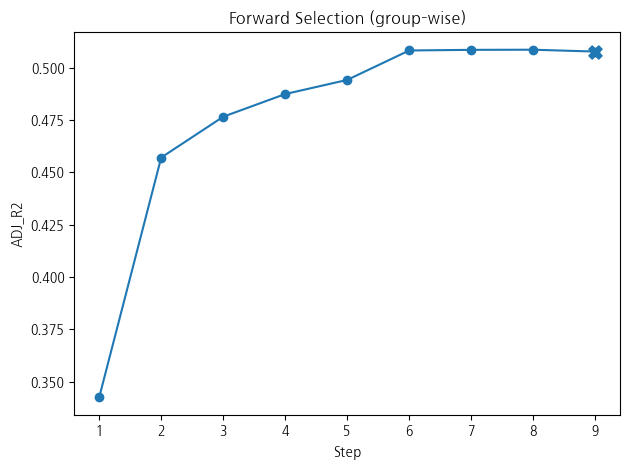

In [8]:
sel = VariableSelector(df, [c for c in df.columns if c!='target'], 'target',
                       criterion="adj_r2", penalty=None, cv=None, problem_type="regression")
vars_sel, fig, hist, final = sel.forward()
print("선정 변수:", vars_sel)
print(final["model_family"])
print(final["equation"])
display(final["coef_table"].head())

선정 변수: ['sex', 'bmi', 'bp', 's1', 's2', 's4', 's5', 's6']
OLS
ŷ = 152.133 + sex*-242.054 + bmi*518.787 + bp*321.502 + s1*-620.647 + s2*353.947 + s4*127.215 + s5*691.924 + s6*67.1429


,coef,std_err,t,p_value,ci_low,ci_high
const,152.133484,2.570640,59.181182,1.238447e-209,147.081001,157.185968
sex,-242.053917,60.742741,-3.984903,7.920141e-05,-361.441209,-122.666624
bmi,518.786943,66.354651,7.818396,4.111084e-14,388.369680,649.204206
bp,321.502112,64.075750,5.017532,7.654828e-07,195.563932,447.440291
s1,-620.647339,204.744134,-3.031331,2.580881e-03,-1023.063285,-218.231393


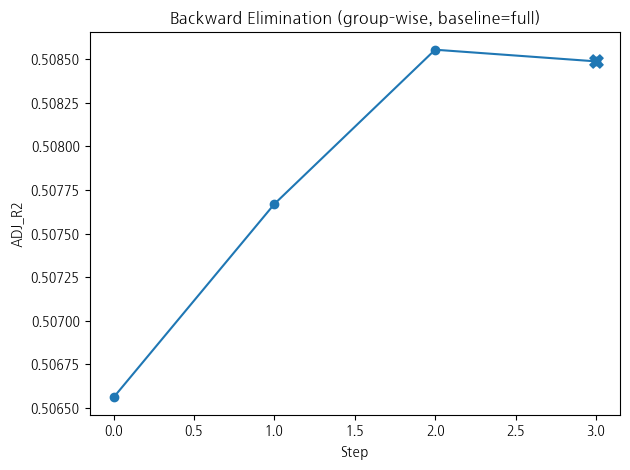

In [9]:
sel = VariableSelector(df, [c for c in df.columns if c!='target'], 'target',
                       criterion="adj_r2", penalty=None, cv=None, problem_type="regression")
vars_sel, fig, hist, final = sel.backward()
print("선정 변수:", vars_sel)
print(final["model_family"])
print(final["equation"])
display(final["coef_table"].head())

선정 변수: ['bmi', 's5', 'bp', 's1']
OLS
ŷ = 152.133 + bmi*605.711 + s5*645.692 + bp*271.276 + s1*-206.67


,coef,std_err,t,p_value,ci_low,ci_high
const,152.133484,2.625473,57.945173,3.193262e-207,146.973360,157.293608
bmi,605.711203,64.008891,9.462923,1.873430e-19,479.907659,731.514747
s5,645.692279,71.407229,9.042394,5.030845e-18,505.347988,786.036570
bp,271.276306,62.369763,4.349484,1.700049e-05,148.694317,393.858296
s1,-206.669533,64.503099,-3.204025,1.454431e-03,-333.444397,-79.894670


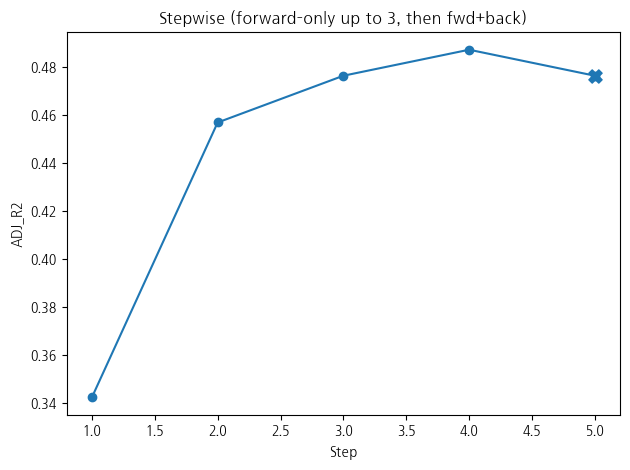

In [10]:
sel = VariableSelector(df, [c for c in df.columns if c!='target'], 'target',
                       criterion="adj_r2", penalty=None, cv=None, problem_type="regression")
vars_sel, fig, hist, final = sel.stepwise()
print("선정 변수:", vars_sel)
print(final["model_family"])
print(final["equation"])
display(final["coef_table"].head())

선정 변수: ['bmi', 's5']
Lasso
ŷ = 152.133 + bmi*369.442 + s5*309.308


,coef
const,152.133484
bmi,369.442208
s5,309.308318


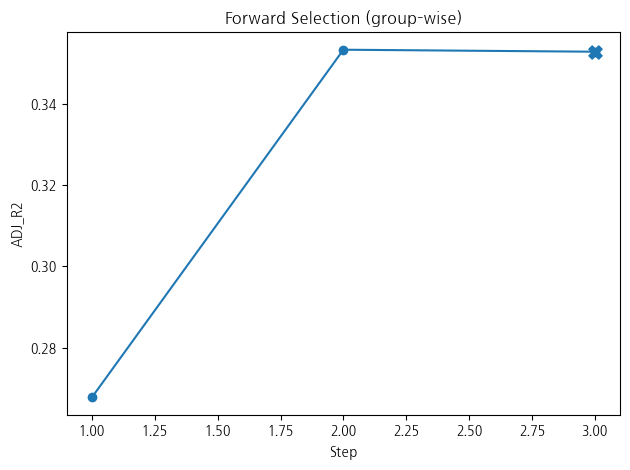

In [11]:
sel = VariableSelector(df, [c for c in df.columns if c!='target'], 'target',
                       criterion="adj_r2", penalty="l1", cv=None, problem_type="regression")
vars_sel, fig, hist, final = sel.forward()
print("선정 변수:", vars_sel)
print(final["model_family"])
print(final["equation"])
display(final["coef_table"].head())

선정 변수: ['bmi', 's5']
Lasso
ŷ = 152.133 + bmi*369.442 + s5*309.308


,coef
const,152.133484
bmi,369.442208
s5,309.308318


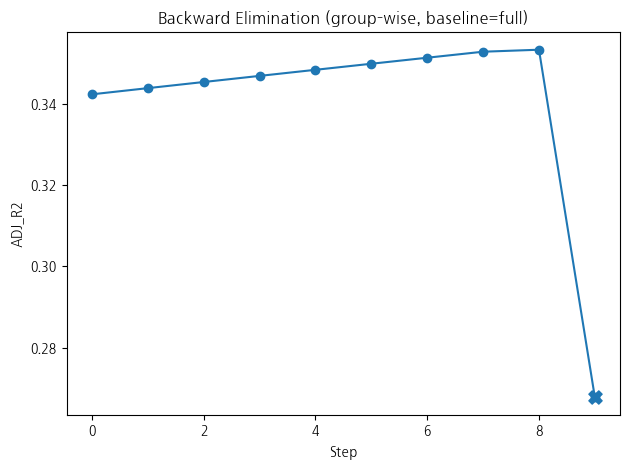

In [12]:
sel = VariableSelector(df, [c for c in df.columns if c!='target'], 'target',
                       criterion="adj_r2", penalty="l1", cv=None, problem_type="regression")
vars_sel, fig, hist, final = sel.backward()
print("선정 변수:", vars_sel)
print(final["model_family"])
print(final["equation"])
display(final["coef_table"].head())

선정 변수: ['bmi', 's5']
Lasso
ŷ = 152.133 + bmi*369.442 + s5*309.308


,coef
const,152.133484
bmi,369.442208
s5,309.308318


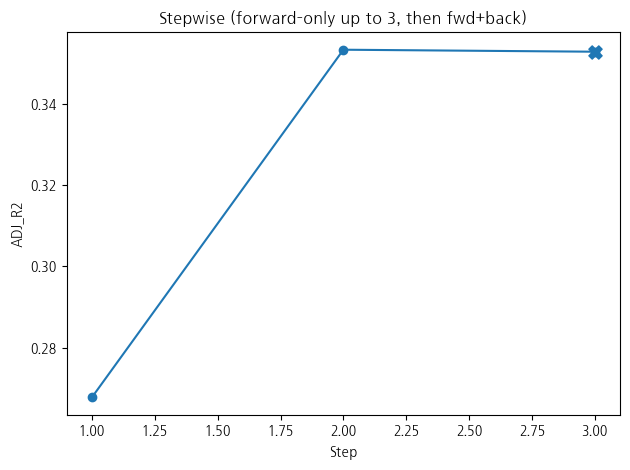

In [13]:
sel = VariableSelector(df, [c for c in df.columns if c!='target'], 'target',
                       criterion="adj_r2", penalty="l1", cv=None, problem_type="regression")
vars_sel, fig, hist, final = sel.stepwise()
print("선정 변수:", vars_sel)
print(final["model_family"])
print(final["equation"])
display(final["coef_table"].head())

선정 변수: ['bmi', 's5', 'bp', 's3']
Ridge
ŷ = 152.133 + bmi*331.012 + s5*306.201 + bp*215.725 + s3*-178.559


,coef
const,152.133484
bmi,331.012283
s5,306.200558
bp,215.724512
s3,-178.559242


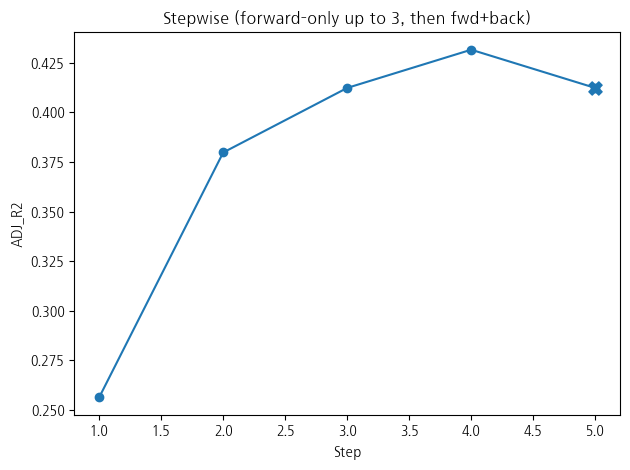

In [14]:
sel = VariableSelector(df, [c for c in df.columns if c!='target'], 'target',
                       criterion="adj_r2", penalty="l2", cv=None, problem_type="regression")
vars_sel, fig, hist, final = sel.stepwise()
print("선정 변수:", vars_sel)
print(final["model_family"])
print(final["equation"])
display(final["coef_table"].head())

선정 변수: ['bmi', 's5']
Lasso
ŷ = 152.133 + bmi*369.442 + s5*309.308


,coef
const,152.133484
bmi,369.442208
s5,309.308318


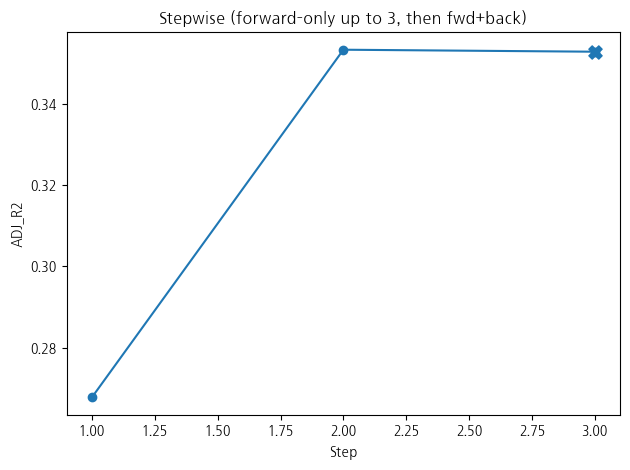

In [15]:
sel = VariableSelector(df, [c for c in df.columns if c!='target'], 'target',
                       criterion="adj_r2", penalty="l1", cv=3)
vars_sel, fig, hist, final = sel.stepwise()
print("선정 변수:", vars_sel)
print(final["model_family"])
print(final["equation"])
display(final["coef_table"].head())

In [16]:
from sklearn.datasets import load_iris
iris = load_iris(as_frame=True)
df = iris.frame.rename(columns={"target":"y"})   # y ∈ {0,1,2}

In [17]:
df['y'] = df['y'].replace(2,1)

In [21]:
df['y'].value_counts()

y
1    100
0     50
Name: count, dtype: int64

In [20]:
sel = VariableSelector(
    df=df,
    indep_vars=[c for c in df.columns if c!="y"],
    dep_var="y",
    criterion="pseudo_r2",   # 다항은 'aic' 또는 'pseudo_r2'
    penalty=None,            # 규제화 없이 → MNLogit 사용 (AIC, p-value 제공)
    # cv=5,                    # 선택: CV accuracy/logloss(AUC-OVR 가능 시)
    cv=None,                    # 선택: CV accuracy/logloss(AUC-OVR 가능 시)
    problem_type="auto",
    show_last_attempt=True
)
vars_sel, fig, hist_df, final = sel.forward()

c:\Users\10007166\AppData\Local\anaconda3\envs\auto_eda\Lib\site-packages\statsmodels\discrete\discrete_model.py:227: PerfectSeparationWarning: Perfect separation or prediction detected, parameter may not be identified
  warnings.warn(msg, category=PerfectSeparationWarning)
c:\Users\10007166\AppData\Local\anaconda3\envs\auto_eda\Lib\site-packages\statsmodels\discrete\discrete_model.py:227: PerfectSeparationWarning: Perfect separation or prediction detected, parameter may not be identified
  warnings.warn(msg, category=PerfectSeparationWarning)
c:\Users\10007166\AppData\Local\anaconda3\envs\auto_eda\Lib\site-packages\statsmodels\discrete\discrete_model.py:227: PerfectSeparationWarning: Perfect separation or prediction detected, parameter may not be identified
  warnings.warn(msg, category=PerfectSeparationWarning)
c:\Users\10007166\AppData\Local\anaconda3\envs\auto_eda\Lib\site-packages\statsmodels\discrete\discrete_model.py:227: PerfectSeparationWarning: Perfect separation or predictio

LinAlgError: Singular matrix